# 12. Why Do Grade Swings Between Semesters Come with More Dropout?

**Round 3 feedback:** *do more tests on the grade-swing result (slide 30) and explain why it happens.*

Notebook 06 (section 6.5) showed a U-shape: students whose grade changes the most between Semester 1 and Semester 2, in **either** direction, drop out more often. The feedback asked *why*. We check five explanations:

| # | Explanation | Test |
|---|---|---|
| 12.2 | The quartile cut points created the pattern | Deciles, percent change, quartiles within each course |
| 12.3 | Regression to the mean: improvers just started low | Starting grade by quartile |
| 12.4 | Different kinds of students swing | Profile of each quartile |
| 12.5–12.6 | **The grade measure itself:** a student can pass fewer units and still see their average rise | Pass-rate change by quartile; logistic models with and without it |
| 12.7 | Is it useful for prediction? | Add grade change to the model, paired cross-validation |

Same sample as 06: the 3,512 students with a nonzero grade in both semesters.

All tests use the full engaged sample; 12.7 uses cross-validation on the training split only (stratified 80/20, `random_state=42`), so the holdout set stays untouched.

## 12.0 Setup

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.proportion import proportion_confint

from src.models import get_logistic_regression
from src.plotting import OUTCOME_PALETTE
from src.preprocessing import (
    TARGET_COL,
    build_model_pipeline,
    get_feature_availability_sets,
    load_data,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
ALPHA = 0.05
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
y = df[TARGET_COL]
print(df.shape)

(4424, 37)


## 12.1 Recreate the quartiles from notebook 06

In [3]:
SEM1, SEM2 = "Curricular units 1st sem", "Curricular units 2nd sem"
d = df[(df[f"{SEM1} (grade)"] > 0) & (df[f"{SEM2} (grade)"] > 0)].copy()
d["Grade change"] = d[f"{SEM2} (grade)"] - d[f"{SEM1} (grade)"]      # positive = improved
d["GPA decline"] = -d["Grade change"]                                # same as notebook 06
QUART_LABELS = ["Q1 (most improved)", "Q2", "Q3", "Q4 (steepest decline)"]
d["Quartile"] = pd.qcut(d["GPA decline"], 4, labels=QUART_LABELS)
d["Dropout"] = (d[TARGET_COL] == "Dropout").astype(int)

# Units passed and pass rate (approved / enrolled) in each semester
for s, prefix in [("1", SEM1), ("2", SEM2)]:
    d[f"Approved S{s}"] = d[f"{prefix} (approved)"]
    d[f"Enrolled S{s}"] = d[f"{prefix} (enrolled)"]
    d[f"Pass rate S{s}"] = (d[f"Approved S{s}"] / d[f"Enrolled S{s}"]).clip(upper=1)
d["Change in units passed"] = d["Approved S2"] - d["Approved S1"]
d["Change in units enrolled"] = d["Enrolled S2"] - d["Enrolled S1"]
d["Change in pass rate"] = d["Pass rate S2"] - d["Pass rate S1"]

print("Students:", len(d), "| any missing pass rate:", int(d[["Pass rate S1", "Pass rate S2"]].isna().sum().sum()))
print("Quartile cut points (GPA decline):", d["GPA decline"].quantile([.25, .5, .75]).round(2).tolist())
display(d.groupby("Quartile", observed=True)["Dropout"].agg(["mean", "size"]).round(3))

Students: 3512 | any missing pass rate: 0
Quartile cut points (GPA decline): [-0.64, -0.0, 0.65]


,mean,size
Quartile,,
Q1 (most improved),0.192,880
Q2,0.151,1105
Q3,0.177,649
Q4 (steepest decline),0.249,878


## 12.2 Is the U-shape an artifact of how we grouped students?

,Raw change (06),Percent change,Within each course
Q1 (most improved),19.2%,19.6%,18.6%
Q2,15.1%,14.8%,17.8%
Q3,17.7%,16.9%,17.4%
Q4 (steepest decline),24.9%,25.5%,22.5%


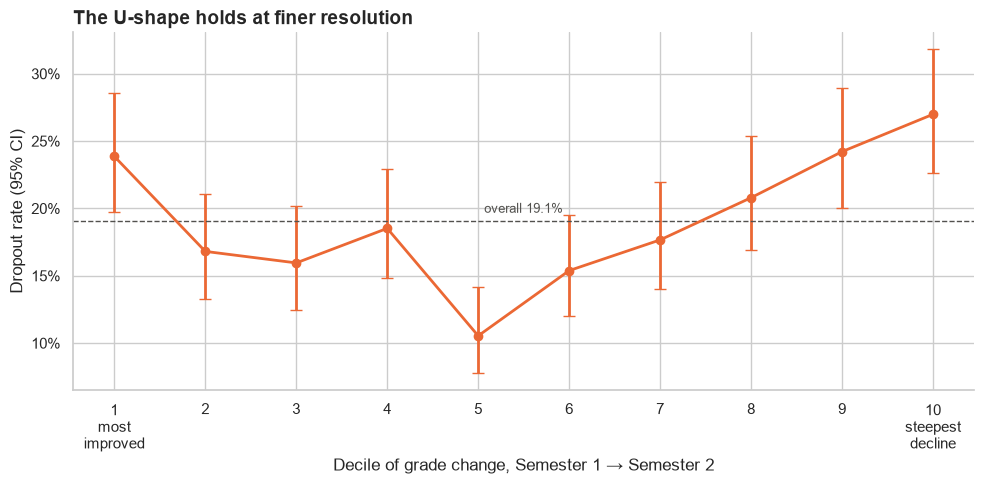

In [4]:
def rate_with_ci(groups):
    out = d.groupby(groups, observed=True)["Dropout"].agg(["sum", "size"])
    out["Dropout rate"] = out["sum"] / out["size"]
    ci = out.apply(lambda r: proportion_confint(r["sum"], r["size"], method="wilson"), axis=1)
    out["CI low"], out["CI high"] = zip(*ci)
    return out

# Deciles of the raw change (rank first, so ties at 0 don't merge groups)
d["Decile"] = pd.qcut(d["GPA decline"].rank(method="first"), 10, labels=range(1, 11))
deciles = rate_with_ci("Decile")

# Percent change instead of raw points
d["Pct quartile"] = pd.qcut(d["GPA decline"] / d[f"{SEM1} (grade)"], 4, labels=QUART_LABELS)
# Quartiles within each course (grading scales differ by program)
d["Within-course quartile"] = (d.groupby("Course")["GPA decline"]
                               .transform(lambda s: np.ceil(s.rank(method="first", pct=True) * 4))
                               .map(dict(zip([1.0, 2.0, 3.0, 4.0], QUART_LABELS))))

robust = pd.DataFrame({
    "Raw change (06)": d.groupby("Quartile", observed=True)["Dropout"].mean(),
    "Percent change": d.groupby("Pct quartile", observed=True)["Dropout"].mean(),
    "Within each course": d.groupby("Within-course quartile")["Dropout"].mean().reindex(QUART_LABELS),
})
display(robust.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(1, 11)
ax.errorbar(x, deciles["Dropout rate"],
            yerr=[deciles["Dropout rate"] - deciles["CI low"], deciles["CI high"] - deciles["Dropout rate"]],
            fmt="o-", color=OUTCOME_PALETTE["Dropout"], capsize=4, lw=2)
ax.axhline(d["Dropout"].mean(), color="#52514e", ls="--", lw=1)
ax.text(5.5, d["Dropout"].mean() + 0.004, f"overall {d['Dropout'].mean():.1%}", ha="center", va="bottom", fontsize=9, color="#52514e")
ax.set_xticks(x, ["1\nmost\nimproved"] + [str(i) for i in range(2, 10)] + ["10\nsteepest\ndecline"])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Dropout rate (95% CI)")
ax.set_xlabel("Decile of grade change, Semester 1 → Semester 2")
ax.set_title("The U-shape holds at finer resolution", loc="left", fontsize=14, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "feedback_grade_change_deciles.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 12.2:** the U-shape isn't an artifact of the cut points. Deciles show the same shape (highest at both ends, lowest near "no change"), and so do percent change and raw change. Within-course quartiles **flatten the improving side** (the most-improved group is close to the middle), while the steepest-decline group stays highest. So part of the "improvers drop out more" effect comes from comparing students across programs that grade differently. The decline side is robust.

## 12.3–12.4 Regression to the mean, and who swings

In [5]:
profile_cols = {
    f"{SEM1} (grade)": "Sem 1 grade",
    f"{SEM2} (grade)": "Sem 2 grade",
    "Pass rate S1": "Sem 1 pass rate",
    "Pass rate S2": "Sem 2 pass rate",
    "Change in units passed": "Change in units passed",
    "Change in units enrolled": "Change in units enrolled",
    "Age at enrollment": "Age at enrollment",
    "Debtor": "Debtor (share)",
    "Tuition fees up to date": "Tuition up to date (share)",
    "Scholarship holder": "Scholarship (share)",
    "Dropout": "Dropout rate",
}
profile = d.groupby("Quartile", observed=True)[list(profile_cols)].mean().rename(columns=profile_cols).T
display(profile.round(3))

Quartile,Q1 (most improved),Q2,Q3,Q4 (steepest decline)
Sem 1 grade,12.120,12.789,12.841,13.264
Sem 2 grade,13.465,12.971,12.510,11.916
Sem 1 pass rate,0.844,0.869,0.881,0.827
Sem 2 pass rate,0.824,0.847,0.855,0.787
Change in units passed,-0.081,-0.204,-0.302,-0.327
Change in units enrolled,0.035,-0.084,-0.148,-0.080
Age at enrollment,22.889,22.153,23.251,22.527
Debtor (share),0.086,0.073,0.112,0.116
Tuition up to date (share),0.931,0.948,0.920,0.900
Scholarship (share),0.265,0.346,0.263,0.247


**Reading 12.3–12.4:**

- **Some regression to the mean:** the most-improved group started lowest (Sem 1 grade ≈ 12.1) and the steepest-decline group started highest (≈ 13.3). That's why notebook 06 controls for the Sem 1 grade; the U-shape survived that control.
- **The swing groups are not very different on Day 1 characteristics.** Age is similar across quartiles. The steepest-decline group has slightly more debtors and fewer students with tuition up to date, and the stable Q2 group has the most scholarship holders. These are modest differences.
- **The bigger clue is in the units:** students in every quartile pass fewer units in Semester 2 on average, but the drop is largest in Q4. Section 12.5 shows why this matters for the improving side too.

## 12.5 What the "grade" actually measures

The dataset describes the semester grade as a *"grade average (0–20)"*. Two checks show it's an **average over the units the student passed only**:

- Portugal's pass mark is 10/20, and almost no nonzero grade is below 10.
- A student has a nonzero grade **if and only if** they passed at least one unit.

That has a big consequence: if a student **fails or drops the hard units** in Semester 2 and passes only the easier ones, their grade average can **go up** even though they're doing worse overall. So "most improved" can hide a student who is falling behind.

In [6]:
for s, prefix in [("Semester 1", SEM1), ("Semester 2", SEM2)]:
    g, a = df[f"{prefix} (grade)"], df[f"{prefix} (approved)"]
    print(f"{s}: nonzero grades below 10 = {int(((g > 0) & (g < 10)).sum())} "
          f"(lowest nonzero grade {g[g > 0].min()}) | "
          f"grade > 0 but 0 units passed = {int(((g > 0) & (a == 0)).sum())} | "
          f"grade = 0 but units passed > 0 = {int(((g == 0) & (a > 0)).sum())}")

Semester 1: nonzero grades below 10 = 1 (lowest nonzero grade 9.8) | grade > 0 but 0 units passed = 0 | grade = 0 but units passed > 0 = 0
Semester 2: nonzero grades below 10 = 0 (lowest nonzero grade 10.0) | grade > 0 but 0 units passed = 0 | grade = 0 but units passed > 0 = 0


,Dropout rate (units passed held or rose),Dropout rate (units passed fell),n (units passed held or rose),n (units passed fell)
Quartile,,,,
Q1 (most improved),13.9%,33.3%,640,240
Q2,10.2%,32.5%,862,243
Q3,11.8%,29.8%,434,215
Q4 (steepest decline),18.3%,38.5%,590,288


Mean change in units passed and Sem 2 pass rate, by quartile and final outcome:


Change in units passed                   Pass rate S2  \
Target                               Dropout Enrolled Graduate      Dropout   
Quartile                                                                      
Q1 (most improved)                     -0.59    -0.21     0.12         0.58   
Q2                                     -0.58    -0.25    -0.11         0.65   
Q3                                     -0.65    -0.34    -0.19         0.66   
Q4 (steepest decline)                  -0.75    -0.39    -0.09         0.58   

                                         
Target                Enrolled Graduate  
Quartile                                 
Q1 (most improved)        0.70     0.94  
Q2                        0.73     0.92  
Q3                        0.76     0.94  
Q4 (steepest decline)     0.69     0.94

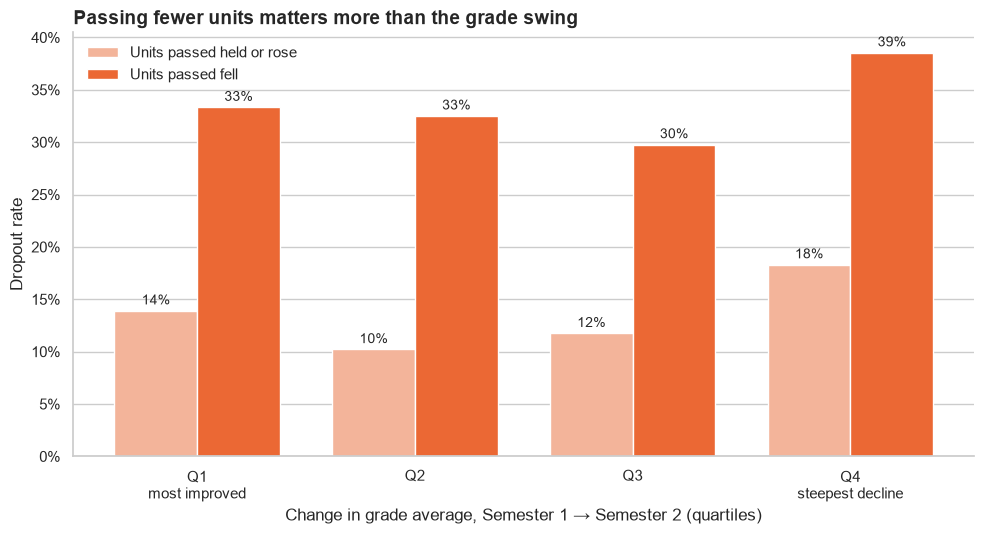

In [7]:
d["Units passed fell"] = d["Change in units passed"] < 0
split = (d.groupby(["Quartile", "Units passed fell"], observed=True)["Dropout"]
         .agg(["mean", "size"]).unstack("Units passed fell"))
split.columns = [f"{'Dropout rate' if m == 'mean' else 'n'} ({'units passed fell' if f else 'units passed held or rose'})"
                 for m, f in split.columns]
display(split.style.format({c: "{:.1%}" for c in split.columns if "rate" in c}))

by_outcome = (d.groupby(["Quartile", TARGET_COL], observed=True)
              [["Change in units passed", "Pass rate S2"]].mean().unstack(TARGET_COL).round(2))
print("Mean change in units passed and Sem 2 pass rate, by quartile and final outcome:")
display(by_outcome)

fig, ax = plt.subplots(figsize=(10, 5.5))
w = 0.38
xq = np.arange(4)
for i, (fell, label, color) in enumerate([(False, "Units passed held or rose", "#f3b49a"),
                                         (True, "Units passed fell", OUTCOME_PALETTE["Dropout"])]):
    rates = d[d["Units passed fell"] == fell].groupby("Quartile", observed=True)["Dropout"].mean()
    bars = ax.bar(xq + (i - 0.5) * w, rates.to_numpy(), w, color=color, label=label)
    for b, v in zip(bars, rates.to_numpy()):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.006, f"{v:.0%}", ha="center", fontsize=10)
ax.set_xticks(xq, ["Q1\nmost improved", "Q2", "Q3", "Q4\nsteepest decline"])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Dropout rate")
ax.set_xlabel("Change in grade average, Semester 1 → Semester 2 (quartiles)")
ax.set_title("Passing fewer units matters more than the grade swing", loc="left", fontsize=14, fontweight="bold")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "feedback_grade_change_by_units_passed.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 12.5:** in every quartile, students who passed **fewer** units in Semester 2 drop out about 2–3 times as often as students who held steady. Dropouts in the "most improved" group lost about 0.6 passed units on average and passed only about 58% of their Semester 2 units, even though their grade average went up. Among students whose units passed held or rose, the U-shape is much weaker (10–14% for Q1–Q3), though Q4 is still highest at 18%. Section 12.6 tests this formally.

## 12.6 Does the U-shape survive once we account for units passed?

Four nested logistic models for dropout (decline = Sem 1 grade − Sem 2 grade):

1. **Base:** decline + decline² + Sem 1 grade (the notebook 06 model)
2. **+ Controls:** course, age, debtor, tuition up to date, scholarship, gender
3. **+ Pass rate:** Sem 1 pass rate and change in pass rate
4. **+ Units:** change in units passed and change in units enrolled (instead of pass rate)

If the U-shape is really about units passed, the decline² term should lose significance in models 3–4.

In [8]:
m = d.rename(columns={
    f"{SEM1} (grade)": "sem1_grade", "Age at enrollment": "age",
    "Tuition fees up to date": "tuition", "Scholarship holder": "scholarship",
    "Pass rate S1": "pass_rate_s1", "Change in pass rate": "d_pass_rate",
    "Change in units passed": "d_passed", "Change in units enrolled": "d_enrolled",
})
m["decline"] = m["GPA decline"]
m["decline_sq"] = m["decline"] ** 2

FORMULAS = {
    "1. Base (notebook 06)": "Dropout ~ decline + decline_sq + sem1_grade",
    "2. + Controls": "Dropout ~ decline + decline_sq + sem1_grade + C(Course) + age + Debtor + tuition + scholarship + Gender",
}
FORMULAS["3. + Pass rate"] = FORMULAS["2. + Controls"] + " + pass_rate_s1 + d_pass_rate"
FORMULAS["4. + Units passed/enrolled"] = FORMULAS["2. + Controls"] + " + pass_rate_s1 + d_passed + d_enrolled"

fits, rows = {}, []
for name, f in FORMULAS.items():
    fit = smf.logit(f, data=m).fit(disp=0, maxiter=200)
    fits[name] = fit
    row = {"Model": name, "AIC": fit.aic}
    for term in ["decline", "decline_sq", "d_pass_rate", "d_passed", "d_enrolled"]:
        if term in fit.params:
            row[f"{term} coef"] = fit.params[term]
            row[f"{term} p"] = fit.pvalues[term]
    rows.append(row)

u_tests = pd.DataFrame(rows).set_index("Model")
display(u_tests.style.format("{:.3g}", na_rep=""))

lr = 2 * (fits["3. + Pass rate"].llf - fits["2. + Controls"].llf)
print(f"Likelihood-ratio test, adding pass-rate terms to model 2: LR = {lr:.1f}, df = 2, "
      f"p = {stats.chi2.sf(lr, 2):.2g}")

,AIC,decline coef,decline p,decline_sq coef,decline_sq p,d_pass_rate coef,d_pass_rate p,d_passed coef,d_passed p,d_enrolled coef,d_enrolled p
Model,,,,,,,,,,,
1. Base (notebook 06),3.18e+03,0.348,5.95e-16,0.0965,9.64e-09,,,,,,
2. + Controls,2.6e+03,0.259,1.02e-07,0.0593,0.00122,,,,,,
3. + Pass rate,2.29e+03,0.0313,0.556,-0.0314,0.111,-3.51,1.26e-31,,,,
4. + Units passed/enrolled,2.3e+03,0.0336,0.527,-0.0265,0.177,,,-0.547,2.89e-30,0.428,4.95e-09


Likelihood-ratio test, adding pass-rate terms to model 2: LR = 317.6, df = 2, p = 1.1e-69


**Reading 12.6:**

- **Models 1–2:** the U-shape is strong and survives course, age, and financial controls (decline² stays positive and significant).
- **Models 3–4:** once the change in **pass rate** (or units passed and enrolled) is in the model, **both the decline and decline² terms stop being significant**, and the model fits much better (AIC drops by about 300; the likelihood-ratio test is p < 0.001).

So the grade swing isn't a separate risk factor. **It's a side effect of how the grade is measured:** the grade average only covers units the student passed, so when a student starts passing fewer units, their average can move in either direction. What actually predicts dropout is **falling behind on units**.

## 12.7 Does grade change help a predictive model?

The inference above says grade change adds nothing once units are known. To check that directly, add two engineered features to the **Full Data** logistic regression (the only stage where both semesters exist): the absolute grade change and the change in pass rate. Evaluate with repeated stratified 5-fold cross-validation (3 repeats) on the **training split only**, paired across identical folds.

In [9]:
full_cols = get_feature_availability_sets(df)["Full Data"]
# Note: src.preprocessing.build_model_pipeline keeps only the columns named in
# NUMERIC_COLS / CATEGORICAL_COLS / BINARY_COLS. New columns need to be added explicitly (below).
X = df[full_cols].copy()
g1, g2 = df[f"{SEM1} (grade)"], df[f"{SEM2} (grade)"]
both = (g1 > 0) & (g2 > 0)
X["Abs grade change"] = np.where(both, (g2 - g1).abs(), 0.0)          # 0 when a semester has no grade
pr1 = (df[f"{SEM1} (approved)"] / df[f"{SEM1} (enrolled)"].replace(0, np.nan)).clip(upper=1).fillna(0)
pr2 = (df[f"{SEM2} (approved)"] / df[f"{SEM2} (enrolled)"].replace(0, np.nan)).clip(upper=1).fillna(0)
X["Change in pass rate"] = pr2 - pr1

X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = {
    "Macro F1": "f1_macro",
    "Dropout recall": make_scorer(recall_score, labels=["Dropout"], average="macro"),
    "Enrolled recall": make_scorer(recall_score, labels=["Enrolled"], average="macro"),
}
variants = {
    "Full Data": full_cols,
    "+ abs grade change": full_cols + ["Abs grade change"],
    "+ change in pass rate": full_cols + ["Change in pass rate"],
}
cv_scores = {}


def pipeline_with_extras(cols):
    """The shared pipeline only keeps columns listed in src/preprocessing.py, so it would
    silently drop engineered features. Add them as an extra scaled numeric block."""
    pipe = build_model_pipeline(model=get_logistic_regression(random_state=42), feature_cols=cols, scale_numeric=True)
    extras = [c for c in cols if c not in full_cols]
    if extras:
        pipe.named_steps["preprocess"].transformers.append(("extra", StandardScaler(), extras))
    return pipe


for name, cols in variants.items():
    pipe = pipeline_with_extras(cols)
    res = cross_validate(pipe, X_train[cols], y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_scores[name] = {k: res[f"test_{k}"] for k in scoring}


def corrected_t(diff, n_train_frac=0.8):
    """Nadeau-Bengio corrected resampled t-test on paired fold differences."""
    k = len(diff)
    var = np.var(diff, ddof=1) * (1 / k + (1 - n_train_frac) / n_train_frac)
    if var == 0:
        return np.nan
    t = diff.mean() / np.sqrt(var)
    return 2 * stats.t.sf(abs(t), k - 1)


rows = []
base = cv_scores["Full Data"]
for name, sc in cv_scores.items():
    row = {"Model": name}
    for metric in scoring:
        row[metric] = sc[metric].mean()
        if name != "Full Data":
            diff = sc[metric] - base[metric]
            row[f"Δ {metric}"] = diff.mean()
            row[f"p (Δ {metric})"] = corrected_t(diff)
    rows.append(row)
display(pd.DataFrame(rows).set_index("Model").style.format("{:.3f}", na_rep=""))

,Macro F1,Dropout recall,Enrolled recall,Δ Macro F1,p (Δ Macro F1),Δ Dropout recall,p (Δ Dropout recall),Δ Enrolled recall,p (Δ Enrolled recall)
Model,,,,,,,,,
Full Data,0.710,0.738,0.598,,,,,,
+ abs grade change,0.711,0.740,0.599,0.002,0.293,0.002,0.474,0.002,0.731
+ change in pass rate,0.711,0.736,0.602,0.001,0.656,-0.002,0.536,0.004,0.447


**Reading 12.7:** adding the absolute grade change to the Full Data model changes macro F1 and Dropout recall by essentially nothing, and the difference isn't significant. Change in pass rate is the more meaningful feature by the inference above, but the model already has units enrolled and passed for both semesters, so it can mostly work this out on its own. Either way, **grade swings aren't worth adding as a warning flag**; units passed already carry that information.

## 12.8 Answer

**Why do grade swings come with dropout?** Because the semester grade is an average over **passed units only**. When a student starts passing fewer units, their average can jump either way:

- If they drop or fail their hardest units, the average of what's left can **rise** (the "most improved" dropouts).
- If they struggle across the board, it **falls** (the "steepest decline" dropouts).

Once the change in pass rate is in the model, the U-shape disappears (decline and decline² are no longer significant). Grouping within each course also weakens the improving side.

**What this changes in our story:** the risk signal isn't "grades swung." It's "**the student passed fewer of their units.**" That matches notebook 08, where *approved units* were the strongest Semester 1 predictor.

**Limitations:** the grade-average definition is inferred from the data (no nonzero grade under 10, and nonzero grade only when units were passed), not stated in the documentation. This is still association, not cause. The analysis covers only the 3,512 students with grades in both semesters.

## 12.9 Summary for the final presentation

| Question | What we tested | Finding |
|---|---|---|
| Why do grade swings signal dropout? | Deciles, percent change, within-course quartiles, quartile profiles, the grade definition, nested logistic models, predictive test | The grade averages **passed units only**, so passing fewer units can move it either way. Controlling for pass-rate change removes the U-shape. **The real signal is falling behind on units**, not the grade swing |

Figures: `reports/figures/feedback_grade_change_deciles.png`, `reports/figures/feedback_grade_change_by_units_passed.png`